# Exploratory Data Analysis: Telco Customer Churn

**Goal:** understand who churns before modelling, and justify the preprocessing and feature choices.

EDA uses the **training split only**, so nothing learned here leaks information from the validation or test sets.


In [2]:
import os
os.chdir("..")  # run from the repo root so data/ paths resolve

import matplotlib.pyplot as plt
import pandas as pd

from src.data.ingestion import DataIngestion

train_path, _, _ = DataIngestion().initiate_data_ingestion()
df = pd.read_csv(train_path)
df["churned"] = (df["Churn"] == "Yes").astype(int)


def churn_rate_by(col):
    """Churn rate and customer count for each value of a column, highest churn first."""
    return (
        df.groupby(col, observed=True)["churned"]
        .agg(churn_rate="mean", customers="size")
        .sort_values("churn_rate", ascending=False)
        .round(3)
    )

## 1. Data overview

In [3]:
print(df.shape)
df.head()

(5704, 22)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,churned
0,3540-RZJYU,Female,0,No,No,15,Yes,No,Fiber optic,Yes,...,No,Yes,No,Month-to-month,No,Electronic check,86.20,1270.2,Yes,1
1,3313-QKNKB,Male,0,Yes,No,59,Yes,Yes,Fiber optic,No,...,No,No,Yes,One year,No,Electronic check,85.55,5084.65,Yes,1
2,7408-OFWXJ,Female,0,Yes,Yes,72,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Two year,No,Credit card (automatic),89.80,6510.45,No,0
3,7669-LCRSD,Male,0,Yes,Yes,12,Yes,No,DSL,No,...,No,Yes,No,Month-to-month,Yes,Mailed check,56.30,628.65,No,0
4,1121-QSIVB,Female,0,No,Yes,44,Yes,Yes,DSL,No,...,No,Yes,Yes,One year,Yes,Mailed check,77.55,3471.1,No,0


In [4]:
df.dtypes

customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
churned               int64
dtype: object

**Takeaway:** one row per customer, with numeric fields (tenure, charges), yes/no service flags and a few multi-category fields. `TotalCharges` is stored as text, not a number (see section 6).

## 2. How common is churn?

Churn rate: 26.5%


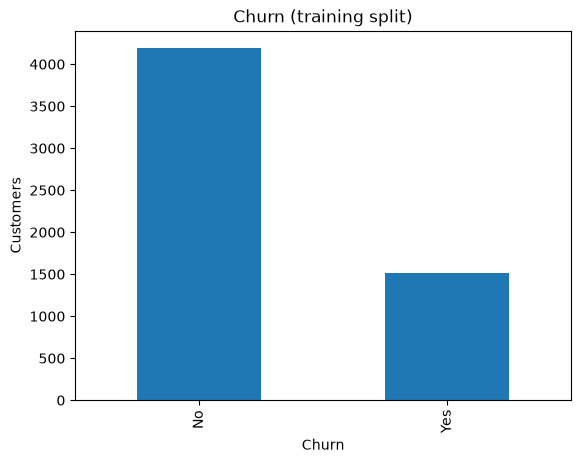

In [5]:
rate = df["churned"].mean()
print(f"Churn rate: {rate:.1%}")

df["Churn"].value_counts().plot(kind="bar", title="Churn (training split)")
plt.ylabel("Customers")
plt.show()

**Takeaway:** roughly 1 in 4 customers churn (≈27%). The classes are imbalanced, so accuracy is misleading (always predicting "stays" scores ≈73%). This is why the model uses `class_weight="balanced"` and is evaluated with ROC-AUC, PR-AUC and churn recall.

## 3. Churn by contract type

In [6]:
churn_rate_by("Contract")

,churn_rate,customers
Contract,,
Month-to-month,0.427,3135
One year,0.112,1211
Two year,0.029,1358


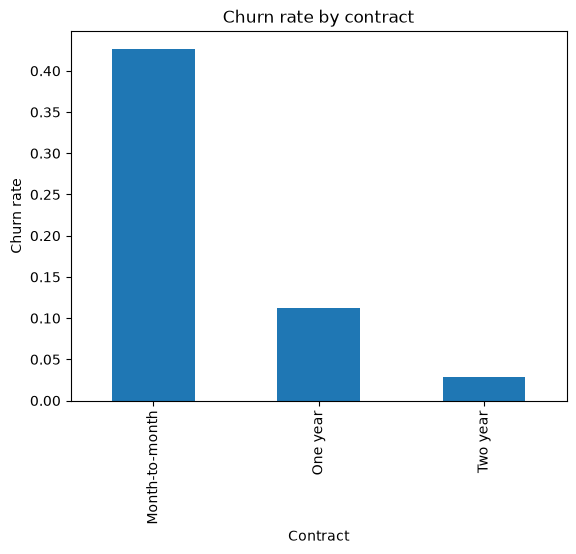

In [7]:
churn_rate_by("Contract")["churn_rate"].plot(kind="bar", title="Churn rate by contract")
plt.ylabel("Churn rate")
plt.show()

**Takeaway:** month-to-month customers churn far more (42.7%) than one-year (11.2%) or two-year (2.9%) customers. Contract type is one of the strongest signals, and SHAP confirms it.

## 4. Churn by tenure

In [8]:
df["tenure_band"] = pd.cut(
    df["tenure"],
    bins=[0, 6, 12, 24, 48, 72],
    labels=["0-6", "7-12", "13-24", "25-48", "49-72"],
    include_lowest=True,
)
churn_rate_by("tenure_band").sort_index()

,churn_rate,customers
tenure_band,,
0-6,0.530,1187
7-12,0.368,581
13-24,0.285,822
25-48,0.202,1289
49-72,0.096,1825


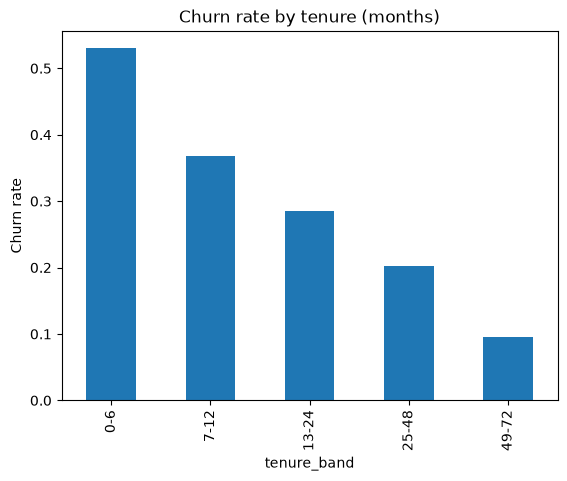

In [9]:
churn_rate_by("tenure_band").sort_index()["churn_rate"].plot(
    kind="bar", title="Churn rate by tenure (months)"
)
plt.ylabel("Churn rate")
plt.show()

**Takeaway:** churn is concentrated in the first months: customers in their first 6 months churn at roughly 50%, falling steadily with tenure. Tenure is the single strongest driver in the model's SHAP explanations.

## 5. Churn by internet service and payment method

In [10]:
churn_rate_by("InternetService")

,churn_rate,customers
InternetService,,
Fiber optic,0.413,2506
DSL,0.192,1982
No,0.081,1216


In [11]:
churn_rate_by("PaymentMethod")

,churn_rate,customers
PaymentMethod,,
Electronic check,0.448,1914
Mailed check,0.194,1296
Bank transfer (automatic),0.169,1243
Credit card (automatic),0.157,1251


**Takeaway:** fiber optic customers churn about twice as often as DSL customers (≈40% vs ≈19%), and customers paying by electronic check churn far more (≈45%) than those on automatic payments (≈15–17%). Both appear among the top SHAP drivers.

## 6. TotalCharges: blank values and redundancy with tenure

In [12]:
blank = df["TotalCharges"].str.strip() == ""
print(f"Blank TotalCharges: {blank.sum()} rows")
df.loc[blank, ["tenure", "MonthlyCharges", "TotalCharges"]]

Blank TotalCharges: 8 rows


,tenure,MonthlyCharges,TotalCharges
183,0,25.75,
2410,0,73.35,
3159,0,19.70,
3707,0,56.05,
4303,0,20.00,
4873,0,52.55,
5081,0,80.85,
5198,0,61.90,


**Takeaway:** a handful of rows have a blank `TotalCharges`, all with tenure 0: brand-new customers who haven't been billed yet. This is why preprocessing converts the column with `pd.to_numeric(errors="coerce")`.

Correlation tenure vs TotalCharges: 0.83


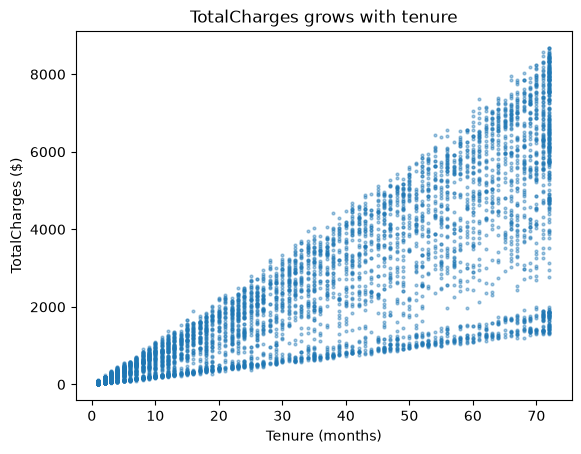

In [13]:
total = pd.to_numeric(df["TotalCharges"], errors="coerce")
print(f"Correlation tenure vs TotalCharges: {df['tenure'].corr(total):.2f}")

plt.scatter(df["tenure"], total, s=4, alpha=0.4)
plt.xlabel("Tenure (months)")
plt.ylabel("TotalCharges ($)")
plt.title("TotalCharges grows with tenure")
plt.show()

**Takeaway:** `TotalCharges` is strongly correlated with tenure (≈0.8), because it's roughly tenure × monthly charge. Keeping it made the logistic regression's SHAP explanations counter-intuitive (low total charges "reducing" risk for a brand-new customer), so it was dropped. Test ROC-AUC changed by only 0.001.

## 7. Monthly charges

In [14]:
df.groupby("Churn")["MonthlyCharges"].describe().round(1)

,count,mean,std,min,25%,50%,75%,max
Churn,,,,,,,,
No,4190.0,61.7,31.1,18.4,25.2,64.9,88.8,118.8
Yes,1514.0,73.9,25.1,18.8,55.2,79.5,94.1,118.4


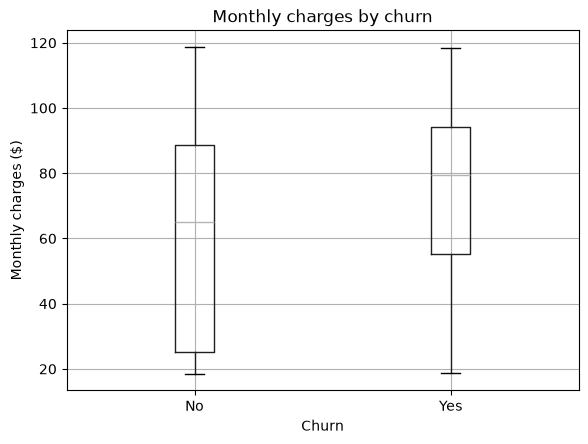

In [15]:
df.boxplot(column="MonthlyCharges", by="Churn")
plt.suptitle("")
plt.title("Monthly charges by churn")
plt.ylabel("Monthly charges ($)")
plt.show()

**Takeaway:** churners pay more per month on average, consistent with the fiber optic effect (fiber plans are the most expensive).

## Summary

- About 27% of customers churn, so evaluation focuses on churn recall, precision and PR-AUC, not accuracy.
- The highest-risk profile: **new customers on month-to-month contracts with fiber optic, paying by electronic check.**
- `TotalCharges` is redundant with tenure and was dropped; its blank values come from brand-new customers.
- These EDA findings match the model's SHAP explanations: tenure, contract type and internet service are the top drivers.